# Capstone Project: Product Return Prediction for an E-Commerce Company

## Task 1 - Understand the business problem

Returns are one of the largest operational costs for an e-commerce marketplace. Every
returned order incurs reverse logistics, inspection, repackaging and refund costs. Our
task is to build a **binary classification** model that predicts, **before an order ships**,
whether it will be **returned**, so the business can act early (improve product info,
recommend prepaid payment, add quality checks, optimise logistics).

**Target variable:** `returned`  (`0` = not returned, `1` = returned)

This notebook follows the 12 tasks in the problem statement and also applies:
**outlier detection & removal**, **`class_weight='balanced'`** for class imbalance,


In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [1]:
#reading the data set
import pandas as pd
df= pd.read_csv("dataset/returns_dataset.csv")
print(df.shape)
df.head()

(12000, 26)


,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,ORD100003,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,...,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,ORD100004,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,...,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0


In [2]:
#cheacking for return items and counting them
df["returned"].value_counts()

returned
0    8355
1    3645
Name: count, dtype: int64

In [3]:
import matplotlib.pyplot as plt

returned
0    8355
1    3645
Name: count, dtype: int64
returned
0    69.62
1    30.38
Name: proportion, dtype: float64


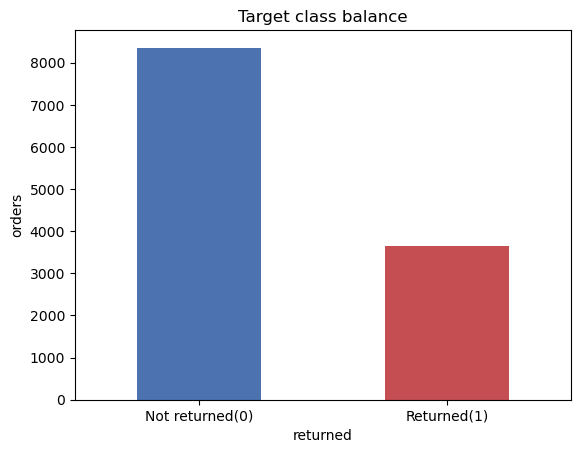

In [4]:
#Target Class Balance Analysis using barchart
counts= df["returned"].value_counts()   #Total 0 and 1 
print(counts)

print((df["returned"].value_counts(normalize=True) * 100).round(2))    #this converts into percentage for easy to compare and understand

ax= counts.plot(kind= "bar", color= ["#4c72b0", "#c44e52"])           #counts.plot is pandas way to plot the data kind= "bar" and store it in ax for later customizes
ax.set_xticklabels(["Not returned(0)", "Returned(1)"], rotation= 0)   #lables for bar charts (xlabel)
ax.set_title("Target class balance")                                  #title
ax.set_ylabel("orders")                                               #ylabel
plt.show()                                                            #show plot

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  12000 non-null  object 
 1   product_category          12000 non-null  object 
 2   sub_category              12000 non-null  object 
 3   brand                     12000 non-null  object 
 4   product_price             12000 non-null  float64
 5   discount_percent          12000 non-null  float64
 6   product_rating            11760 non-null  float64
 7   review_count              11880 non-null  float64
 8   fragile_item              12000 non-null  int64  
 9   warranty_available        12000 non-null  int64  
 10  product_return_rate       12000 non-null  float64
 11  category_return_rate      12000 non-null  float64
 12  brand_return_rate         12000 non-null  float64
 13  defect_rate               12000 non-null  float64
 14  seller

In [6]:
#for numeric summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
product_price,12000.0,964.063342,1678.771489,19.510,328.235,597.470,1105.395,64878.670
discount_percent,12000.0,33.567167,19.378304,0.000,16.800,33.500,50.400,67.000
product_rating,11760.0,3.886505,0.635664,1.600,3.500,3.900,4.300,5.000
review_count,11880.0,69.437205,18.446294,24.000,54.000,69.000,85.000,116.000
fragile_item,12000.0,0.197083,0.397812,0.000,0.000,0.000,0.000,1.000
warranty_available,12000.0,0.446500,0.497150,0.000,0.000,0.000,1.000,1.000
product_return_rate,12000.0,0.132522,0.069787,0.001,0.082,0.134,0.183,0.367
category_return_rate,12000.0,0.120377,0.049559,0.001,0.087,0.120,0.154,0.354
brand_return_rate,12000.0,0.131886,0.059397,0.010,0.090,0.135,0.176,0.322
defect_rate,12000.0,0.060629,0.042730,0.000,0.029,0.051,0.082,0.370


<Axes: >

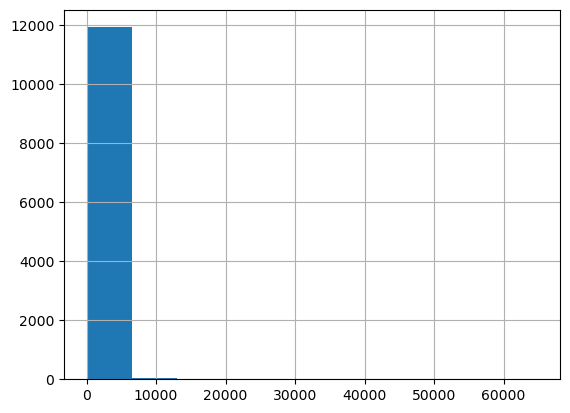

In [7]:
df.product_price.hist()

In [9]:
#looking for null values
df.isnull().sum()

order_id                      0
product_category              0
sub_category                  0
brand                         0
product_price                 0
discount_percent              0
product_rating              240
review_count                120
fragile_item                  0
warranty_available            0
product_return_rate           0
category_return_rate          0
brand_return_rate             0
defect_rate                   0
seller_rating               180
seller_return_rate            0
fulfillment_type              0
payment_method                0
quantity                      0
shipping_distance_km        120
delayed_delivery              0
wishlist_before_purchase      0
product_page_views            0
customer_support_calls        0
chat_interactions             0
returned                      0
dtype: int64

In [14]:
#categorical columns
categorical_columns= ["product_category", "sub_category", "brand", "fulfillment_type", "payment_method"]

for col in categorical_columns:
    print(df[col].value_counts())
    print()


product_category
Fashion        3413
Electronics    2601
Home           1816
Beauty         1453
Sports         1202
Books           910
Toys            605
Name: count, dtype: int64

sub_category
Mobiles           904
Audio             862
Laptops           835
Women             706
Accessories       684
Footwear          681
Men               673
Kids              669
Kitchen           614
Furniture         614
Decor             588
Haircare          505
Skincare          485
Makeup            463
Team Sports       439
Fitness           389
Outdoor           374
Non-Fiction       335
Fiction           288
Academic          287
Outdoor Play      220
Educational       195
Action Figures    190
Name: count, dtype: int64

brand
Brand_26    442
Brand_21    431
Brand_24    427
Brand_1     425
Brand_15    420
Brand_5     418
Brand_22    418
Brand_11    413
Brand_9     411
Brand_30    410
Brand_7     408
Brand_2     407
Brand_19    406
Brand_14    405
Brand_25    403
Brand_4     400
Brand_29

In [15]:
df["product_category"].value_counts()

product_category
Fashion        3413
Electronics    2601
Home           1816
Beauty         1453
Sports         1202
Books           910
Toys            605
Name: count, dtype: int64

##### we are going to do analysis on payment_method like  on payment mode to see how many products are returned in every payment mode

In [16]:
df.columns

Index(['order_id', 'product_category', 'sub_category', 'brand',
       'product_price', 'discount_percent', 'product_rating', 'review_count',
       'fragile_item', 'warranty_available', 'product_return_rate',
       'category_return_rate', 'brand_return_rate', 'defect_rate',
       'seller_rating', 'seller_return_rate', 'fulfillment_type',
       'payment_method', 'quantity', 'shipping_distance_km',
       'delayed_delivery', 'wishlist_before_purchase', 'product_page_views',
       'customer_support_calls', 'chat_interactions', 'returned'],
      dtype='object')

In [17]:
df.groupby(col)["returned"].mean().sort_values(ascending= False)

payment_method
COD            0.505236
Wallet         0.235993
Debit Card     0.228943
Credit Card    0.198724
UPI            0.156847
Name: returned, dtype: float64

##### 
fig = the entire figure (the canvas).

axes = the individual plotting areas.

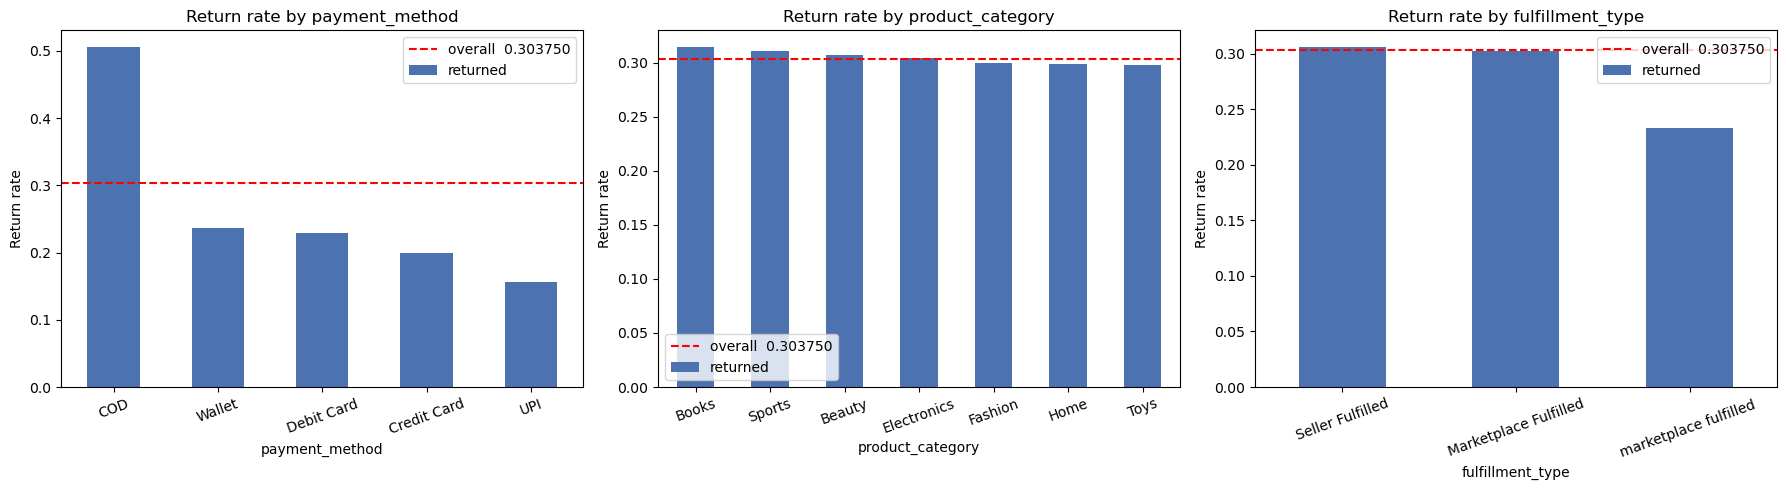

In [30]:
fig, axes= plt.subplots(1, 3, figsize= (18, 5))    #Create three plots in one figure
#plt.subplots(rows, columns)

overall= df["returned"].mean()

for ax, col in zip(axes, ["payment_method", "product_category", "fulfillment_type"]):
    rate= df.groupby(col)["returned"].mean().sort_values(ascending= False)     #calculating and grouping "returned" column in decending order with respect to col
    
    rate.plot(kind= "bar", ax= ax, color= "#4c72b0") #ploting the data into bar
    
    ax.axhline(overall, color= "Red", ls= "--", label= f"overall {overall: 2f}")  #drawing horizontal line here, based on our mean() 
    
    ax.set_title(f"Return rate by {col}")   # with the help of {} it changes every fig name
    ax.set_ylabel("Return rate")
    ax.tick_params(axis= "x", rotation= 20)
    ax.legend()

plt.tight_layout()
plt.show()
     
    

In [31]:
df["returned"]

0        1
1        0
2        0
3        0
4        0
        ..
11995    1
11996    0
11997    0
11998    0
11999    1
Name: returned, Length: 12000, dtype: int64

In [32]:
df.columns

Index(['order_id', 'product_category', 'sub_category', 'brand',
       'product_price', 'discount_percent', 'product_rating', 'review_count',
       'fragile_item', 'warranty_available', 'product_return_rate',
       'category_return_rate', 'brand_return_rate', 'defect_rate',
       'seller_rating', 'seller_return_rate', 'fulfillment_type',
       'payment_method', 'quantity', 'shipping_distance_km',
       'delayed_delivery', 'wishlist_before_purchase', 'product_page_views',
       'customer_support_calls', 'chat_interactions', 'returned'],
      dtype='object')

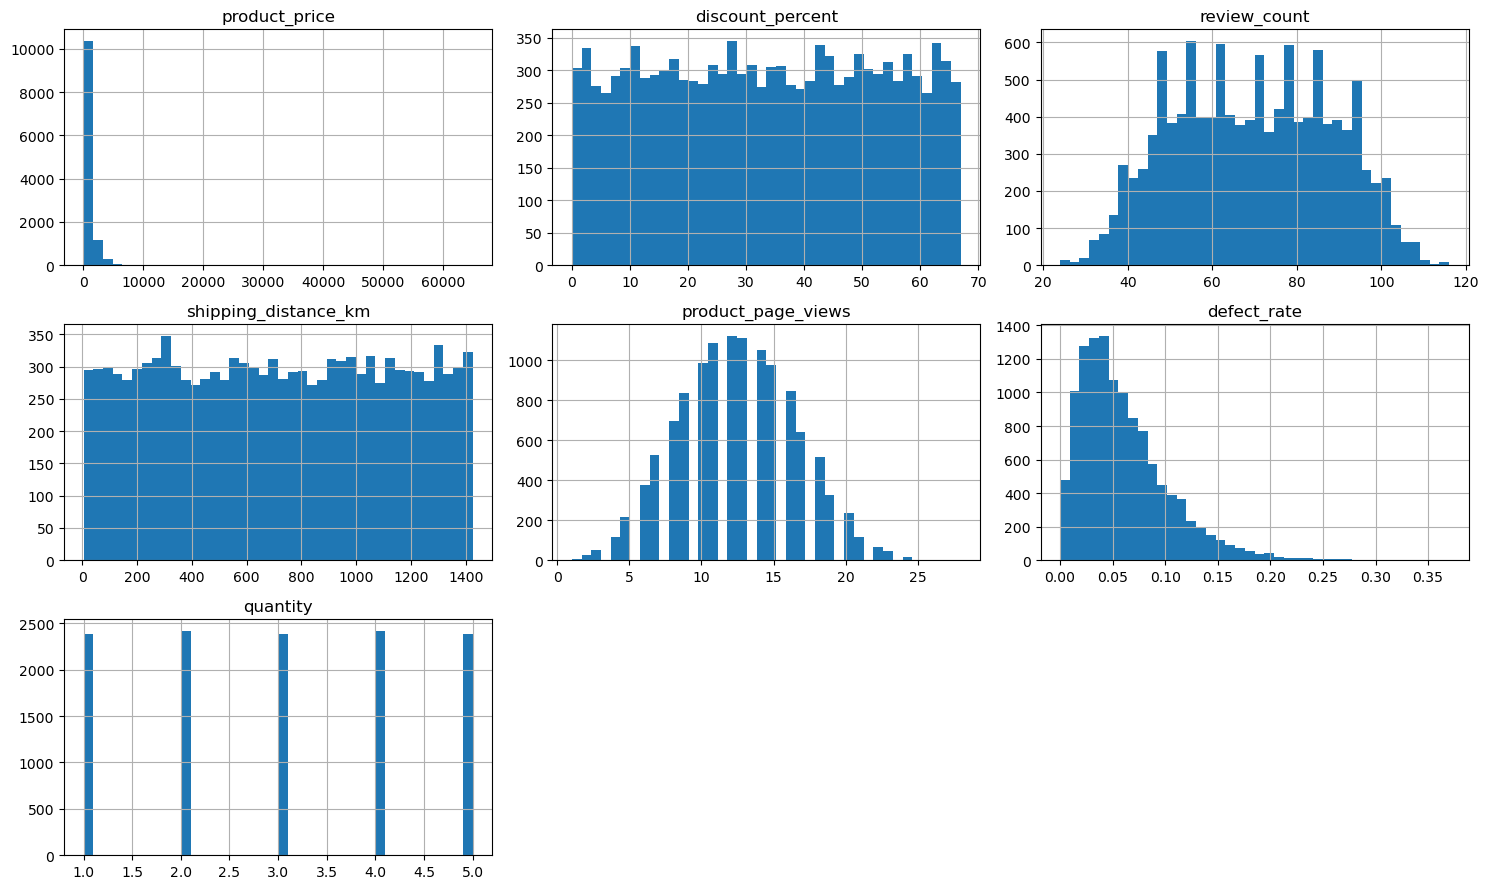

In [33]:
##further stats in the form of histogram

num_show= ["product_price", "discount_percent", "review_count", "shipping_distance_km", "product_page_views", "defect_rate", "quantity"]   #storing in a variable later acess through df[]

df[num_show].hist(figsize=(15, 9), bins= 40)
plt.tight_layout()
plt.show()

In [38]:
df["product_price"].value_counts().sort_index(ascending=False)

product_price
64878.67    1
54530.30    1
51785.32    1
46335.19    1
38309.37    1
           ..
24.60       1
23.98       1
23.62       1
19.83       1
19.51       1
Name: count, Length: 11573, dtype: int64

### Correlation with Target
Bacially we are taking all numerical columns and comparing them with Target variable, like if they changes how much target variable is changing

In [41]:
corr= df.select_dtypes(include=[np.number]).corr()
corr

,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
product_price,1.000000,-0.016544,-0.009996,0.011318,0.004471,-0.005059,-0.004302,-0.006108,-0.003224,-0.020734,0.008962,0.005713,0.000894,0.002893,0.012480,-0.004764,-0.005788,-0.005461,0.002545,-0.003023
discount_percent,-0.016544,1.000000,0.000143,-0.001287,0.007751,-0.014156,-0.003496,0.018814,0.001693,0.005724,-0.006852,-0.011614,-0.000393,-0.004087,0.005830,-0.005076,-0.000921,0.016842,0.001497,0.009022
product_rating,-0.009996,0.000143,1.000000,-0.004054,-0.009272,-0.013554,-0.006133,0.002965,-0.003017,0.001398,-0.008732,0.007746,-0.009657,-0.000152,0.000457,0.015325,0.016439,0.001983,-0.002238,-0.110463
review_count,0.011318,-0.001287,-0.004054,1.000000,0.004870,0.014399,0.009583,-0.000850,0.009161,0.001629,0.004011,0.002190,-0.006908,0.000360,0.008228,-0.009608,-0.002893,-0.003473,0.006936,0.005825
fragile_item,0.004471,0.007751,-0.009272,0.004870,1.000000,0.018553,-0.005197,0.003906,-0.011399,0.000653,-0.010058,0.004545,-0.008517,0.013720,0.009213,-0.000359,0.000184,-0.002178,0.000701,0.258118
warranty_available,-0.005059,-0.014156,-0.013554,0.014399,0.018553,1.000000,0.014906,-0.004160,0.017477,0.005117,0.008828,-0.005481,-0.005895,-0.005424,-0.013420,0.014134,0.015358,0.011117,-0.000900,-0.213782
product_return_rate,-0.004302,-0.003496,-0.006133,0.009583,-0.005197,0.014906,1.000000,0.004466,0.828173,0.002362,0.012690,0.007550,-0.009250,0.000396,-0.001079,-0.009231,0.012313,0.000120,-0.007042,0.312953
category_return_rate,-0.006108,0.018814,0.002965,-0.000850,0.003906,-0.004160,0.004466,1.000000,0.003246,-0.005091,0.006205,0.015878,-0.007067,-0.016087,-0.014060,0.000243,0.005410,-0.005486,-0.004417,-0.006420
brand_return_rate,-0.003224,0.001693,-0.003017,0.009161,-0.011399,0.017477,0.828173,0.003246,1.000000,-0.010206,0.008259,0.001791,-0.012656,-0.006052,-0.004020,-0.010581,0.008980,0.001996,-0.014422,0.336750
defect_rate,-0.020734,0.005724,0.001398,0.001629,0.000653,0.005117,0.002362,-0.005091,-0.010206,1.000000,-0.000128,0.001354,0.000302,0.014904,0.002763,-0.005108,-0.005438,-0.004293,-0.002231,0.073658


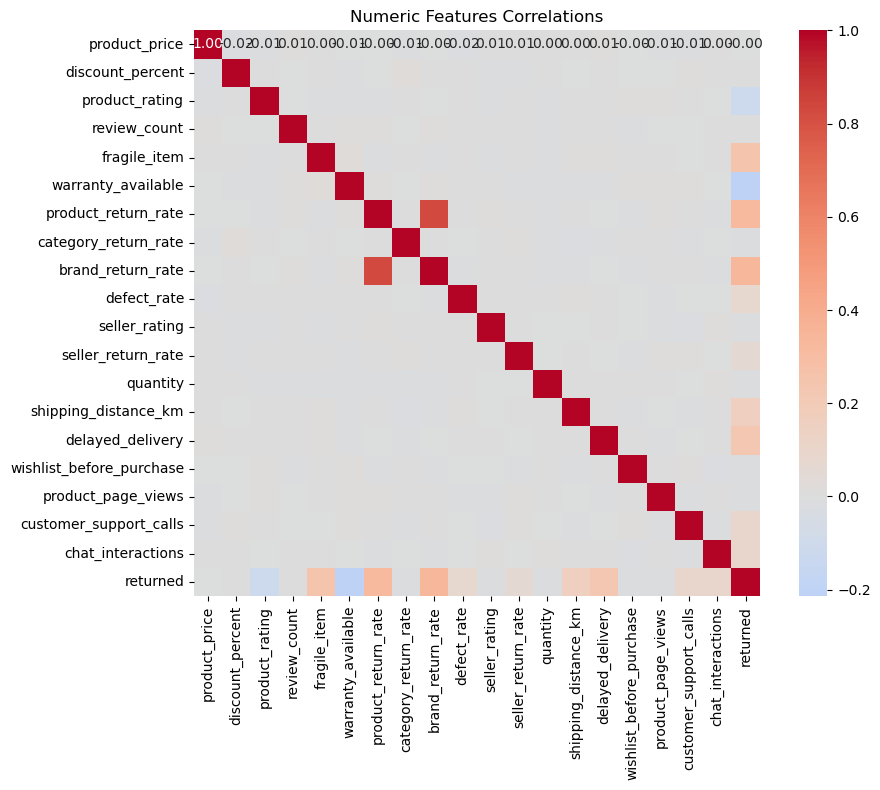

brand_return_rate           0.337
product_return_rate         0.313
fragile_item                0.258
delayed_delivery            0.229
warranty_available         -0.214
shipping_distance_km        0.162
product_rating             -0.110
customer_support_calls      0.094
chat_interactions           0.092
defect_rate                 0.074
seller_return_rate          0.059
product_page_views         -0.014
quantity                   -0.013
seller_rating              -0.010
discount_percent            0.009
wishlist_before_purchase   -0.009
category_return_rate       -0.006
review_count                0.006
product_price              -0.003
Name: returned, dtype: float64


In [49]:
#ploting the Heat Map

plt.figure(figsize=(10, 8))

# Select numerical columns and calculate correlation
corr = df.select_dtypes(include=[np.number]).corr()

# Plot correlation heatmap
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    annot=True,
    fmt=".2f"
)

plt.title("Numeric Features Correlations")
plt.tight_layout()
plt.show()


# Correlation of every feature with returned
target_corr = corr["returned"].drop("returned")

target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
).round(3)

print(target_corr)